In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv(r"C:\Users\Aishwarya\OneDrive\Desktop\projects\zomato data set.csv", encoding='latin1')

In [4]:
df.head()

,Restaurant Name,City,Cuisines,Average Cost for two,Has Table booking,Has Online delivery,Price range,Aggregate rating,Rating text,Votes
0,Le Petit Souffle,Makati City,"French, Japanese, Desserts",1100,Yes,No,3,4.8,Excellent,314
1,Izakaya Kikufuji,Makati City,Japanese,1200,Yes,No,3,4.5,Excellent,591
2,Heat - Edsa Shangri-La,Mandaluyong City,"Seafood, Asian, Filipino, Indian",4000,Yes,No,4,4.4,Very Good,270
3,Ooma,Mandaluyong City,"Japanese, Sushi",1500,No,No,4,4.9,Excellent,365
4,Sambo Kojin,Mandaluyong City,"Japanese, Korean",1500,Yes,No,4,4.8,Excellent,229


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant Name       9551 non-null   str    
 1   City                  9551 non-null   str    
 2   Cuisines              9542 non-null   str    
 3   Average Cost for two  9551 non-null   int64  
 4   Has Table booking     9551 non-null   str    
 5   Has Online delivery   9551 non-null   str    
 6   Price range           9551 non-null   int64  
 7   Aggregate rating      9551 non-null   float64
 8   Rating text           9551 non-null   str    
 9   Votes                 9551 non-null   int64  
dtypes: float64(1), int64(3), str(6)
memory usage: 1.2 MB


In [12]:
df.describe()

,Average Cost for two,Price range,Aggregate rating,Votes
count,9551.000000,9551.000000,9551.000000,9551.000000
mean,1199.210763,1.804837,2.666370,156.909748
std,16121.183073,0.905609,1.516378,430.169145
min,0.000000,1.000000,0.000000,0.000000
25%,250.000000,1.000000,2.500000,5.000000
50%,400.000000,2.000000,3.200000,31.000000
75%,700.000000,2.000000,3.700000,131.000000
max,800000.000000,4.000000,4.900000,10934.000000


In [13]:
df.isnull().sum()

Restaurant Name         0
City                    0
Cuisines                9
Average Cost for two    0
Has Table booking       0
Has Online delivery     0
Price range             0
Aggregate rating        0
Rating text             0
Votes                   0
dtype: int64

In [14]:
df.dropna(inplace=True)

In [15]:
df.drop_duplicates(inplace=True)

In [18]:
print(df.columns)

Index(['Restaurant Name', 'City', 'Cuisines', 'Average Cost for two',
       'Has Table booking', 'Has Online delivery', 'Price range',
       'Aggregate rating', 'Rating text', 'Votes'],
      dtype='str')


In [20]:
df['Aggregate rating'] = df['Aggregate rating'].astype(str)

df['Aggregate rating'] = df['Aggregate rating'].str.replace('/5', '', regex=False)

df['Aggregate rating'] = pd.to_numeric(df['Aggregate rating'], errors='coerce')

In [6]:
df.duplicated().sum()

np.int64(43)

In [7]:
df = df.drop_duplicates()

In [9]:
df.shape

(9508, 10)

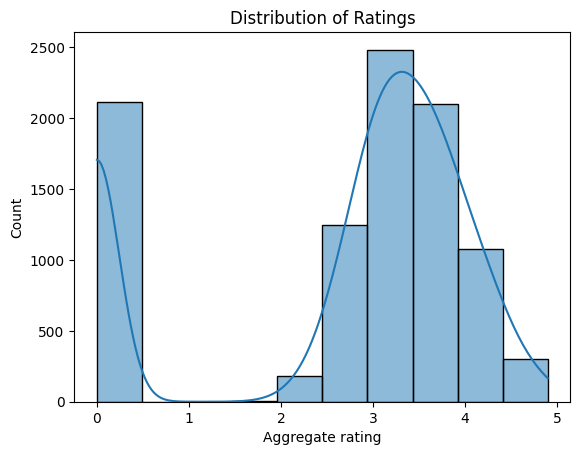

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df['Aggregate rating'], bins=10, kde=True)
plt.title("Distribution of Ratings")
plt.show()

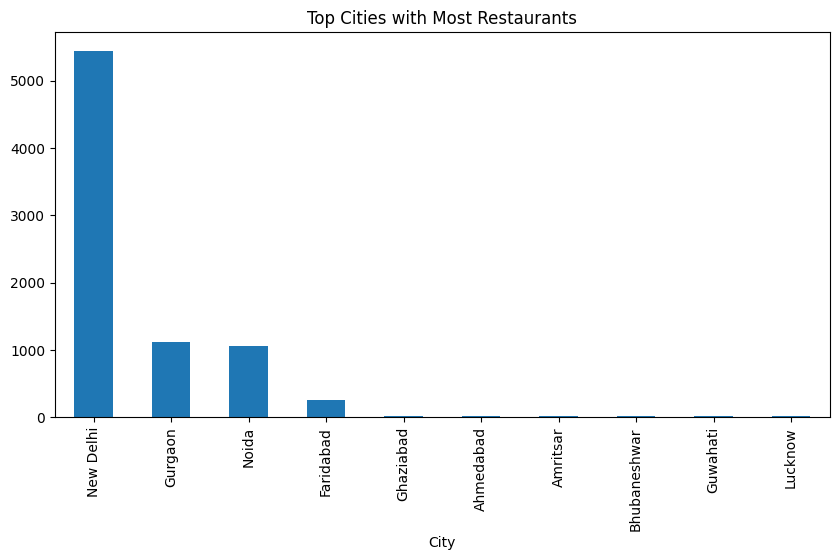

In [12]:
plt.figure(figsize=(10,5))
df['City'].value_counts().head(10).plot(kind='bar')
plt.title("Top Cities with Most Restaurants")
plt.show()

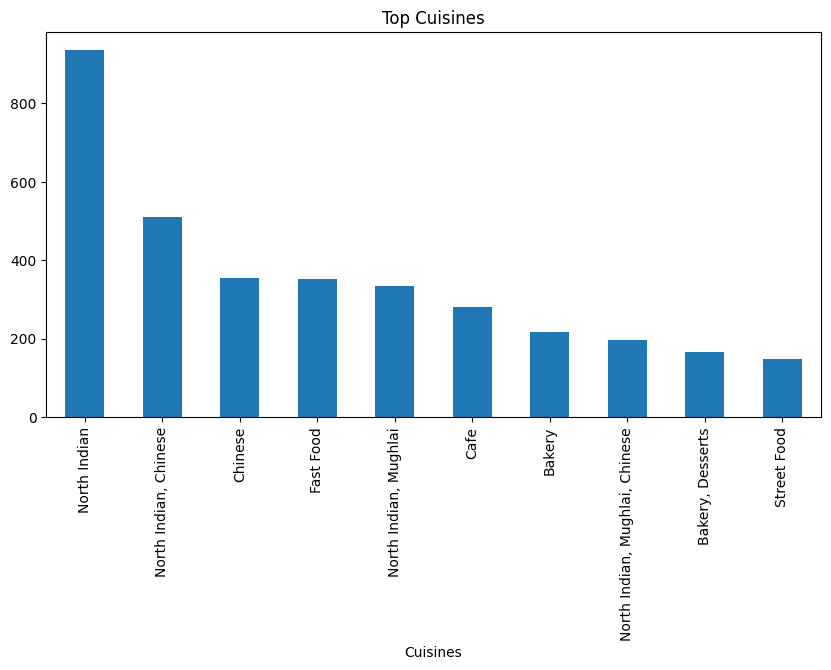

In [13]:
plt.figure(figsize=(10,5))
df['Cuisines'].value_counts().head(10).plot(kind='bar')
plt.title("Top Cuisines")
plt.show()

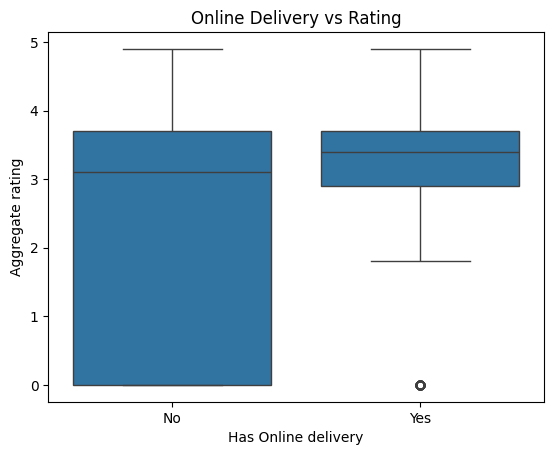

In [17]:
sns.boxplot(x='Has Online delivery', y='Aggregate rating', data=df)
plt.title("Online Delivery vs Rating")
plt.show()

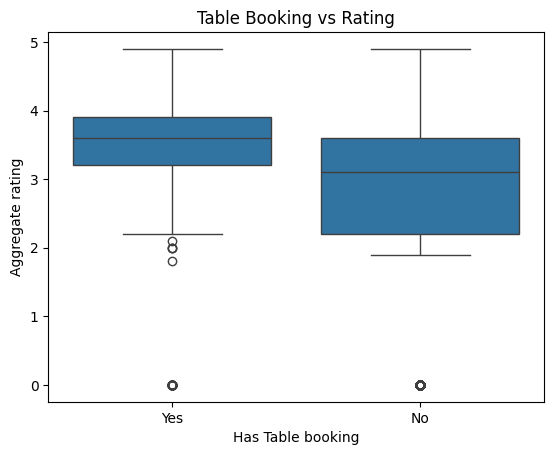

In [19]:
sns.boxplot(x='Has Table booking', y='Aggregate rating', data=df)
plt.title("Table Booking vs Rating")
plt.show()

In [21]:
df['Has Table booking'] = df['Has Table booking'].map({'Yes': 1, 'No': 0})
df['Has Online delivery'] = df['Has Online delivery'].map({'Yes': 1, 'No': 0})

In [22]:
df = df.dropna()

In [24]:
df['Average Cost for two'] = df['Average Cost for two'].replace(',', '', regex=True).astype(float)

In [25]:
df.info()

<class 'pandas.DataFrame'>
Index: 9499 entries, 0 to 9550
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant Name       9499 non-null   str    
 1   City                  9499 non-null   str    
 2   Cuisines              9499 non-null   str    
 3   Average Cost for two  9499 non-null   float64
 4   Has Table booking     9499 non-null   int64  
 5   Has Online delivery   9499 non-null   int64  
 6   Price range           9499 non-null   int64  
 7   Aggregate rating      9499 non-null   float64
 8   Rating text           9499 non-null   str    
 9   Votes                 9499 non-null   int64  
dtypes: float64(2), int64(4), str(4)
memory usage: 1.3 MB


In [26]:
df['City'].nunique()

140

In [27]:
df['Cuisines'].nunique()

1825

In [28]:
df = pd.get_dummies(df, columns=['City'], drop_first=True)

In [29]:
df['Cuisines'] = df['Cuisines'].astype(str)

In [30]:
df['Main_Cuisine'] = df['Cuisines'].apply(lambda x: x.split(',')[0])

In [31]:
df = pd.get_dummies(df, columns=['Main_Cuisine'], drop_first=True)

In [35]:
df.head()

,Restaurant Name,Cuisines,Average Cost for two,Has Table booking,Has Online delivery,Price range,Aggregate rating,Rating text,Votes,City_Agra,...,Main_Cuisine_Tapas,Main_Cuisine_Tea,Main_Cuisine_Tex-Mex,Main_Cuisine_Thai,Main_Cuisine_Tibetan,Main_Cuisine_Turkish,Main_Cuisine_Turkish Pizza,Main_Cuisine_Vietnamese,Main_Cuisine_Western,Main_Cuisine_World Cuisine
0,Le Petit Souffle,"French, Japanese, Desserts",1100.0,1,0,3,4.8,Excellent,314,0,...,0,0,0,0,0,0,0,0,0,0
1,Izakaya Kikufuji,Japanese,1200.0,1,0,3,4.5,Excellent,591,0,...,0,0,0,0,0,0,0,0,0,0
2,Heat - Edsa Shangri-La,"Seafood, Asian, Filipino, Indian",4000.0,1,0,4,4.4,Very Good,270,0,...,0,0,0,0,0,0,0,0,0,0
3,Ooma,"Japanese, Sushi",1500.0,0,0,4,4.9,Excellent,365,0,...,0,0,0,0,0,0,0,0,0,0
4,Sambo Kojin,"Japanese, Korean",1500.0,1,0,4,4.8,Excellent,229,0,...,0,0,0,0,0,0,0,0,0,0


In [33]:
df.info()

<class 'pandas.DataFrame'>
Index: 9499 entries, 0 to 9550
Columns: 266 entries, Restaurant Name to Main_Cuisine_World Cuisine
dtypes: bool(257), float64(2), int64(4), str(3)
memory usage: 3.4 MB


In [36]:
bool_cols = df.select_dtypes(include='bool').columns
df[bool_cols] = df[bool_cols].astype(int)

In [42]:
df.select_dtypes(include='object').columns

C:\Users\Aishwarya\AppData\Local\Temp\ipykernel_5108\3732952691.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include='object').columns


Index(['Restaurant Name', 'Cuisines', 'Rating text'], dtype='str')

In [44]:
df=df.drop(columns=['Restaurant Name','Cuisines','Rating text'])

In [70]:
X = df.drop('Aggregate rating', axis=1)
y = df['Aggregate rating']

In [71]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [72]:
from sklearn.linear_model import LinearRegression

In [73]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [74]:
y_pred = model.predict(X_test)

In [75]:
from sklearn.metrics import mean_absolute_error, r2_score

print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 0.7184443503647806
R2 Score: 0.2828538331242414


In [76]:
y_pred = model.predict(X_test)

In [77]:
from sklearn.ensemble import RandomForestRegressor

In [78]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [79]:
y_pred_rf = rf.predict(X_test)

In [80]:
print("MAE:", mean_absolute_error(y_test, y_pred_rf))
print("R2 Score:", r2_score(y_test, y_pred_rf))

MAE: 0.24297820189183675
R2 Score: 0.91561176120669


In [81]:
print(X.shape)
print(y.shape)
print(X.columns)

(8147, 262)
(8147,)
Index(['Average Cost for two', 'Has Table booking', 'Has Online delivery',
       'Price range', 'Votes', 'City_Agra', 'City_Ahmedabad', 'City_Albany',
       'City_Allahabad', 'City_Amritsar',
       ...
       'Main_Cuisine_Tapas', 'Main_Cuisine_Tea', 'Main_Cuisine_Tex-Mex',
       'Main_Cuisine_Thai', 'Main_Cuisine_Tibetan', 'Main_Cuisine_Turkish',
       'Main_Cuisine_Turkish Pizza', 'Main_Cuisine_Vietnamese',
       'Main_Cuisine_Western', 'Main_Cuisine_World Cuisine'],
      dtype='str', length=262)


In [64]:
df.corr()['Aggregate rating'].sort_values(ascending=False)

Aggregate rating             1.000000
Price range                  0.437233
Votes                        0.313059
Has Online delivery          0.226203
Has Table booking            0.189122
                               ...   
City_Faridabad              -0.087117
Main_Cuisine_Mithai         -0.089702
Main_Cuisine_North Indian   -0.122456
City_Noida                  -0.144137
City_New Delhi              -0.176075
Name: Aggregate rating, Length: 263, dtype: float64

In [68]:
df = df.drop_duplicates()

In [69]:
df.duplicated().sum()

np.int64(0)

In [83]:
import pandas as pd

importance = rf.feature_importances_
features = X.columns

feature_importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importance
})

feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

feature_importance_df.head(10)

,Feature,Importance
4,Votes,0.916980
0,Average Cost for two,0.023314
3,Price range,0.006076
2,Has Online delivery,0.005325
91,City_New Delhi,0.004952
92,City_Noida,0.004115
222,Main_Cuisine_North Indian,0.003411
54,City_Gurgaon,0.002854
1,Has Table booking,0.002032
170,Main_Cuisine_Chinese,0.001948


In [84]:
ascending=False

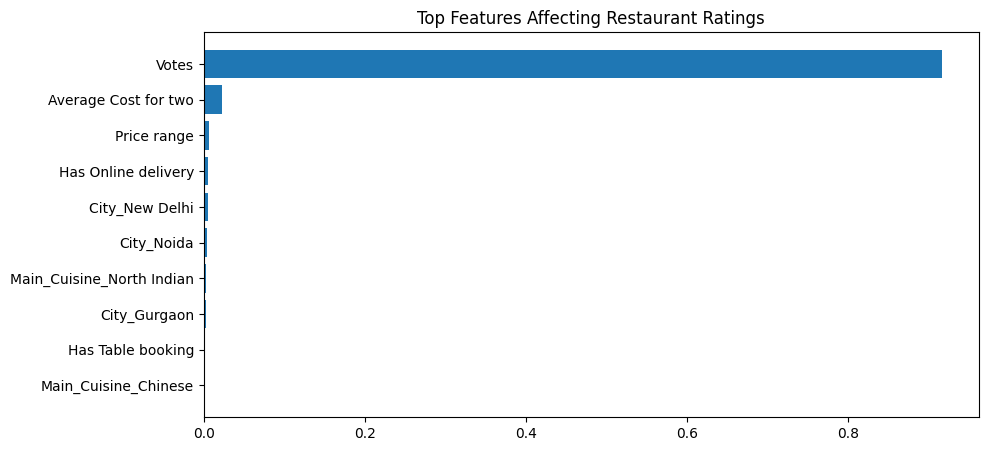

In [85]:
import matplotlib.pyplot as plt

top_features = feature_importance_df.head(10)

plt.figure(figsize=(10,5))
plt.barh(top_features['Feature'], top_features['Importance'])
plt.gca().invert_yaxis()
plt.title("Top Features Affecting Restaurant Ratings")
plt.show()